#### Simulation settings

`Paths`

In [682]:
from pathlib import Path
import numpy as np

ACC_CPP_DIR = Path("/home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp")
BINARY_FILE = ACC_CPP_DIR / "build/runner/acc_sim"
OUTPUT_ROOT = ACC_CPP_DIR / "results"


Select scenario type and file


In [683]:
SCENARIO_MODE = "ncap_2023"  # "recorded" or "ncap_2023"

if SCENARIO_MODE == "recorded":
    EGO_NAME = "object_1"
    SCENARIO_FILE = ACC_CPP_DIR / "../../Data/C_original_1549178.xosc"  
    
    
elif SCENARIO_MODE == "ncap_2023":
    EGO_NAME = "Ego"
    SCENARIO_FILE = (
        ACC_CPP_DIR
        / "../../Data/OSC-NCAP-scenarios/OpenSCENARIO/NCAP"
        / "AEB_C2C_2023/NCAP_AEB_C2C_CCR_2023.xosc"  
    )
    
    

NCAP overrides and shared batch settings


In [684]:
# Used only in ncap_2023 mode
EGO_SPEEDS_KPH = [50,70]
TARGET_SPEED_KPH = 30.0
TARGET_BRAKING_ENABLED = True

# Batch params
MARKOV_SEEDS =  list(np.linspace(42, 100, 5, dtype=int))
MARKOV_MISS_PROBABILITY = 0.1
MARKOV_MEAN_MISSING_SECONDS = 0.5


`Launcher settings`

In [685]:
TIMESTEP_SECONDS = 0.01
TIME_GAP_SECONDS = 1.5  # Native ACC default following time gap.
SET_SPEED_MPS = None  # None uses the scenario's initial ego speed.
STOP_ON_COLLISION = True
DETAILED_LOGS = True
VIEWER = False
NATIVE_REFERENCE = False  # False: target copies; True: live native targets.

# Esmini ObjectSensor: one measurement per simulation timestep.
IDEAL_SENSOR_ENABLED = True  # False keeps all-target copies for validation.
SENSOR_X_METRES = 0.0
SENSOR_Y_METRES = 0.0
SENSOR_Z_METRES = 0.5
SENSOR_HEADING_RADIANS = 0.0
SENSOR_NEAR_RANGE_METRES = 0.0
SENSOR_FAR_RANGE_METRES = 100.0
SENSOR_HORIZONTAL_FOV_RADIANS = np.deg2rad(60.0)  # 60 degrees.



#### Prepare the batch

Choose `SCENARIO_MODE` in the scenario cell:
- `recorded`: uses `C_original` trajectory-defined motion; no NCAP speed/braking arguments or speed sweep. Runs one ideal baseline and every Markov seed.

- `ncap_2023`: uses the supported NCAP 2023 CCR base file; applies speed/braking overrides and runs one ideal baseline + every Markov seed at each `EGO_SPEEDS_KPH` value.

ACC, sensor and Markov settings are shared. No command lines need commenting out when switching modes.


In [686]:
import subprocess
import tempfile

binary = BINARY_FILE.resolve()
scenario = SCENARIO_FILE.resolve()

# Check bin file and xosc file exist
if not binary.is_file() or not scenario.is_file():
    raise FileNotFoundError("Check ACC_CPP_DIR, BINARY_FILE and SCENARIO_FILE.")

# Markov requirements
if MARKOV_SEEDS and (not IDEAL_SENSOR_ENABLED or NATIVE_REFERENCE):
    raise ValueError("Markov requires IDEAL_SENSOR_ENABLED=True and NATIVE_REFERENCE=False.")

if SCENARIO_MODE == "ncap_2023" and not EGO_SPEEDS_KPH:
    raise ValueError("Choose at least one ego speed in EGO_SPEEDS_KPH.")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
batch_dir = Path(tempfile.mkdtemp(prefix="acc_batch_", dir=OUTPUT_ROOT.resolve()))
print("Batch output:", batch_dir)


Batch output: /home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp/results/acc_batch_tp3idu3q


Shared command and batch execution


In [687]:
# Simulation args
command = [
    str(binary), "--scenario", str(scenario),
    "--controller", "acc",
    "--dt", str(TIMESTEP_SECONDS),
    "--time-gap", str(TIME_GAP_SECONDS),
    "--stop-on-collision", str(STOP_ON_COLLISION).lower(),
    "--detailed-logs", str(DETAILED_LOGS).lower(),
    "--viewer", str(VIEWER).lower(),
    "--native-reference", str(NATIVE_REFERENCE).lower(),
]

# Ideal sensor args
command += [
    "--ideal-sensor", str(IDEAL_SENSOR_ENABLED).lower(),
    "--sensor-x-m", str(SENSOR_X_METRES),
    "--sensor-y-m", str(SENSOR_Y_METRES),
    "--sensor-z-m", str(SENSOR_Z_METRES),
    "--sensor-heading-rad", str(SENSOR_HEADING_RADIANS),
    "--sensor-near-m", str(SENSOR_NEAR_RANGE_METRES),
    "--sensor-far-m", str(SENSOR_FAR_RANGE_METRES),
    "--sensor-horizontal-fov-rad", str(SENSOR_HORIZONTAL_FOV_RADIANS),
]

command += ["--ego-name", EGO_NAME]

# These names are specific to the supported NCAP 2023 base scenario.
if SCENARIO_MODE == "ncap_2023":
    command += [
        "--target-speed-kph", str(TARGET_SPEED_KPH),
        "--target-braking", str(TARGET_BRAKING_ENABLED).lower(),
    ]

if SET_SPEED_MPS is not None:
    command += ["--set-speed", str(SET_SPEED_MPS)]
    

# Each entry gets a separate folder, even if a seed is repeated.
run_settings = []

# Recorded mode has one scenario-defined speed, regardless of the NCAP list.
batch_speeds = EGO_SPEEDS_KPH if SCENARIO_MODE == "ncap_2023" else [None]

for ego_speed in batch_speeds:
    run_settings.append((ego_speed, "ideal", 0))
    for seed in MARKOV_SEEDS:
        run_settings.append((ego_speed, "markov", seed))
runs = []


for index, (ego_speed, perception, seed) in enumerate(run_settings):
    model_label = "ideal" if perception == "ideal" else f"markov_seed_{seed}"
    if ego_speed is None:
        label = f"recorded_{model_label}"
    else:
        label = f"ego_{ego_speed:g}_kph_{model_label}"
    output_dir = batch_dir / f"{index:02d}_{label}"
    
    run_command = command + [
        "--output-dir", str(output_dir),
        "--perception", perception,
        "--dropout-p", str(MARKOV_MISS_PROBABILITY if perception == "markov" else 0.0),
        "--mean-missing-s", str(MARKOV_MEAN_MISSING_SECONDS),
        "--seed", str(seed),
    ]
    
    if ego_speed is not None:
        run_command += ["--ego-speed-kph", str(ego_speed)]

    print("-" * 80)
    print(f"Run {index + 1}/{len(run_settings)}: {label}")
    print("-" * 80)
    print(f"{label}: {output_dir}")

    # Remember each completed run 
    subprocess.run(run_command, cwd=ACC_CPP_DIR, check=True)
    runs.append({"label": label, "output_dir": output_dir, "ego_speed_kph": ego_speed})

# clear
from IPython.display import clear_output
clear_output(wait=False)

#### Load results and compare summaries

Runs may end at different times because of collision or the scenario’s own stopping conditions.


In [688]:
import csv
import json
from IPython.display import Markdown, display

if not runs:
    raise ValueError("No completed runs in memory. Run the batch launch cell first.")

for run in runs:
    output_dir = run["output_dir"]
    for filename in ["results", "detections"]:
        with (output_dir / f"{filename}.csv").open(newline="") as file:
            run[filename] = list(csv.DictReader(file))
     
    # Read json summary and config for each run     
    run["summary"] = json.loads((output_dir / "summary.json").read_text())
    run["config"] = json.loads((output_dir / "run_config.json").read_text())

comparison = [
    "| Run | Collision | Min gap (m) | Min TTC (s) | Duration (s) | End reason |",
    "|---|---|---|---|---|---|",
]
for run in runs:
    summary = run["summary"]
    gap = summary["minimum_gap_m"]
    ttc = summary["minimum_ttc_s"]
    gap_text = "—" if gap is None else f"{gap:.2f}"
    ttc_text = "—" if ttc is None else f"{ttc:.2f}"
    comparison.append(
        f"| {run['label']} | {summary['collision']} | {gap_text} | {ttc_text} "
        f"| {summary['duration_s']:.2f} | {summary['end_reason']} |"
    )
display(Markdown("\n".join(comparison)))

print(f"run: {run.keys()}")
# run["summary"]

| Run | Collision | Min gap (m) | Min TTC (s) | Duration (s) | End reason |
|---|---|---|---|---|---|
| ego_50_kph_ideal | False | 11.22 | 6.12 | 8.24 | scenario_stop |
| ego_50_kph_markov_seed_42 | False | 11.12 | 7.35 | 8.05 | scenario_stop |
| ego_50_kph_markov_seed_56 | False | 7.55 | 2.29 | 9.16 | scenario_stop |
| ego_50_kph_markov_seed_71 | False | 10.67 | 7.01 | 8.04 | scenario_stop |
| ego_50_kph_markov_seed_85 | False | 10.69 | 2.77 | 8.17 | scenario_stop |
| ego_50_kph_markov_seed_100 | False | 11.22 | 6.12 | 8.24 | scenario_stop |
| ego_70_kph_ideal | False | 11.07 | 4.38 | 11.46 | scenario_stop |
| ego_70_kph_markov_seed_42 | False | 11.12 | 4.34 | 11.31 | scenario_stop |
| ego_70_kph_markov_seed_56 | False | 10.26 | 4.27 | 11.09 | scenario_stop |
| ego_70_kph_markov_seed_71 | False | 10.56 | 3.27 | 11.29 | scenario_stop |
| ego_70_kph_markov_seed_85 | False | 10.38 | 4.53 | 11.34 | scenario_stop |
| ego_70_kph_markov_seed_100 | False | 11.09 | 4.99 | 11.27 | scenario_stop |

run: dict_keys(['label', 'output_dir', 'ego_speed_kph', 'results', 'detections', 'summary', 'config'])


#### Compare signals




In [689]:
%matplotlib widget
import matplotlib.pyplot as plt

for run in runs:
    with (run["output_dir"] / "truth.csv").open(newline="") as file:
        run["truth"] = list(csv.DictReader(file))


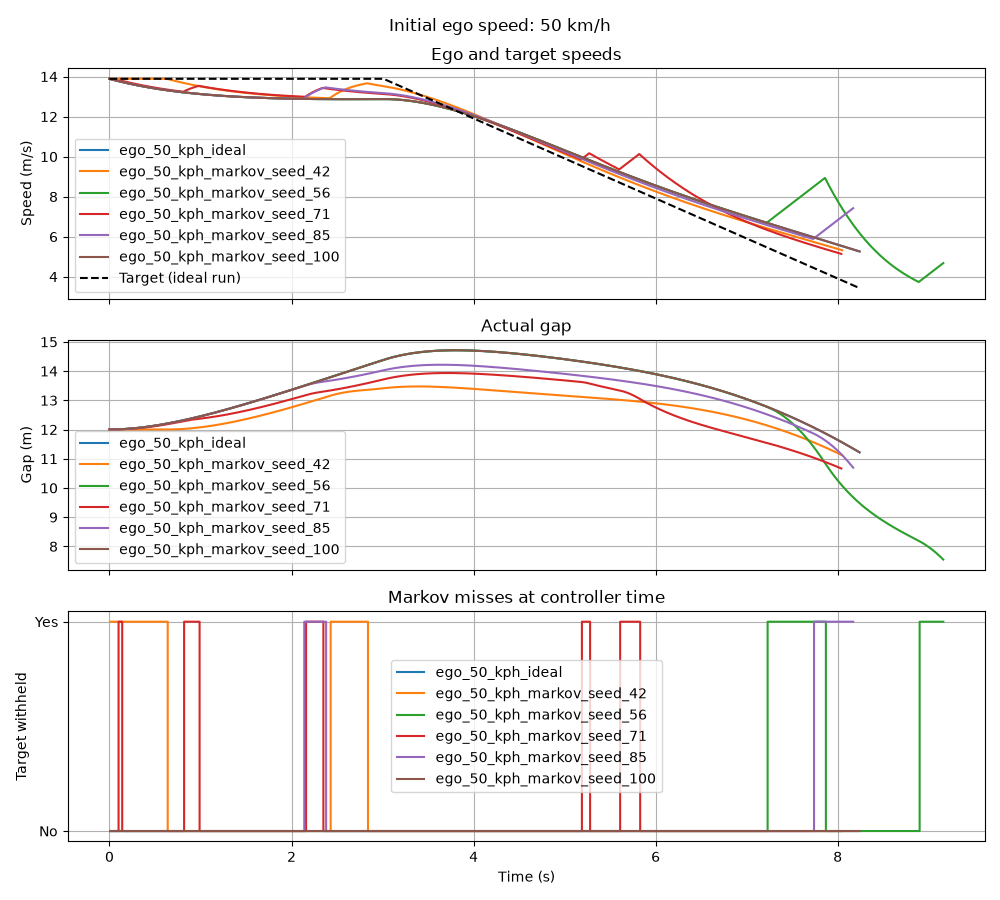

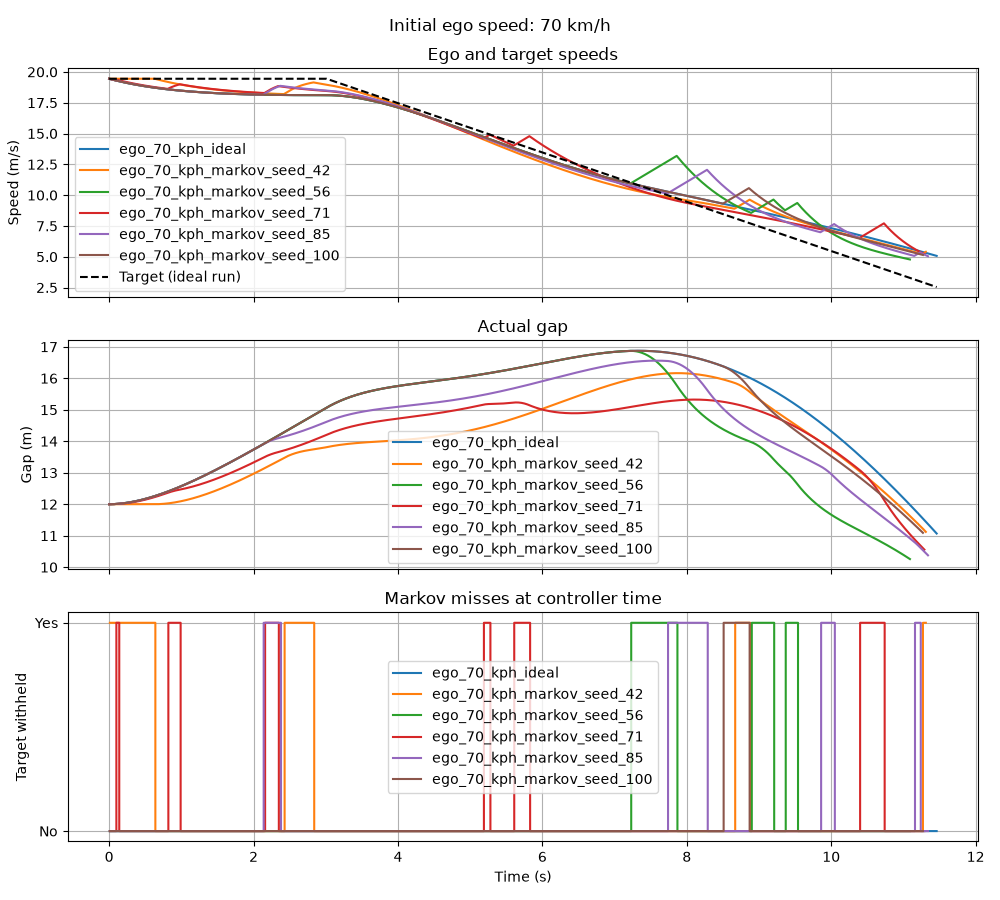

In [690]:
for ego_speed in sorted({run["ego_speed_kph"] for run in runs}):
    speed_runs = [run for run in runs if run["ego_speed_kph"] == ego_speed]
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    if ego_speed is None:
        fig.suptitle("Recorded scenario: trajectory-defined initial speed")
    else:
        fig.suptitle(f"Initial ego speed: {ego_speed:g} km/h")

    for run in speed_runs:
        label = run["label"]
        ego = [row for row in run["truth"] if row["role"] == "ego"]
        axes[0].plot(
            [float(row["time_s"]) for row in ego],
            [float(row["speed_mps"]) for row in ego],
            label=label,
        )
        axes[1].plot(
            [float(row["time_s"]) for row in run["results"]],
            [float(row["truth_min_gap_m"]) if row["truth_min_gap_m"] else float("nan")
             for row in run["results"]],
            label=label,
        )
        axes[2].step(
            [float(row["controller_time_s"]) for row in run["detections"]],
            [bool(json.loads(row["dropped_target_ids"])) for row in run["detections"]],
            where="post",
            label=label,
        )

    target = [row for row in speed_runs[0]["truth"] if row["object_id"] == "1"]
    axes[0].plot(
        [float(row["time_s"]) for row in target],
        [float(row["speed_mps"]) for row in target],
        "k--", label="Target (ideal run)",
    )
    axes[0].set_title("Ego and target speeds")
    axes[0].set_ylabel("Speed (m/s)")
    axes[1].set_title("Actual gap")
    axes[1].set_ylabel("Gap (m)")
    axes[2].set_title("Markov misses at controller time")
    axes[2].set_ylabel("Target withheld")
    axes[2].set_yticks([0, 1], ["No", "Yes"])
    axes[2].set_xlabel("Time (s)")

    for axis in axes:
        axis.legend()
        axis.grid()

    plt.tight_layout()
    plt.show()


#### Replay the batch together 
Build once with `python3 tools/build_native.py --viewer`

Using saved recordings, without rerunning ACC. Tab switches vehicles; Space pauses.

In [691]:
import sys
from importlib import reload
sys.path.insert(0, str(ACC_CPP_DIR))
from tools import replay_batch

reload(replay_batch)
replay_dir = replay_batch.replay_batch(runs, ACC_CPP_DIR)
clear_output(wait=False)